<a href="https://colab.research.google.com/github/boddanapurna6-oss/Deep-Learning-skills/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – Baseline Detector Evaluation (YOLOv8n on COCO traffic classes)
Run the cells top to bottom (Runtime → Run all). The first run downloads the COCO annotations (~250 MB) and ~250 images, so it takes a few minutes.

In [1]:
# ---- Cell 0: install / imports ----
import os, sys, json, time, shutil, random, zipfile, subprocess, urllib.request
from concurrent.futures import ThreadPoolExecutor

try:
    from ultralytics import YOLO
except ImportError:
    print("Installing ultralytics...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])
    from ultralytics import YOLO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker
from PIL import Image

plt.rcParams["figure.dpi"] = 110
print("Week 7 environment initialised (Ultralytics YOLO ready).")

Installing ultralytics...
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Week 7 environment initialised (Ultralytics YOLO ready).


In [2]:
# ---- Cell 1: folders + real COCO val2017 annotations ----
week5_dir = "./coco_week5_audit"
week6_dir = "./coco_week6_prep"
week7_dir = "./coco_week7_baseline"
for d in [f"{week5_dir}/annotations", f"{week5_dir}/sample_images", week7_dir]:
    os.makedirs(d, exist_ok=True)

ann_json_path = f"{week5_dir}/annotations/instances_val2017.json"

# (a leftover tiny mock file from an earlier run is replaced by the real one)
if not os.path.exists(ann_json_path) or os.path.getsize(ann_json_path) < 5_000_000:
    zip_path = f"{week5_dir}/annotations_trainval2017.zip"
    print("Downloading COCO 2017 annotations (~250 MB, one-off)...")
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", zip_path)
    with zipfile.ZipFile(zip_path) as z, z.open("annotations/instances_val2017.json") as src, open(ann_json_path, "wb") as dst:
        shutil.copyfileobj(src, dst)
    os.remove(zip_path)
print("Annotations ready:", ann_json_path)

Annotations ready: ./coco_week5_audit/annotations/instances_val2017.json


In [3]:
# ---- Cell 2: load annotations + class mappings ----
with open(ann_json_path, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

img_id_to_info = {img["id"]: img for img in coco_data["images"]}
file_to_info   = {img["file_name"]: img for img in coco_data["images"]}

TARGET_CLASSES = ["person", "bicycle", "car", "motorcycle", "bus", "truck", "traffic light", "stop sign"]
sorted_target_cats = sorted([c for c in coco_data["categories"] if c["name"] in TARGET_CLASSES], key=lambda x: x["id"])
coco_id_to_contiguous = {c["id"]: idx for idx, c in enumerate(sorted_target_cats)}
contiguous_to_name    = {idx: c["name"] for idx, c in enumerate(sorted_target_cats)}

# official 80-class COCO index (0..79, what YOLO outputs) -> our 8-class index (0..7)
sorted_all_cats = sorted(coco_data["categories"], key=lambda x: x["id"])
assert len(sorted_all_cats) == 80, "Expected the full 80-class COCO annotation file"
coco80_to_subset8 = {
    idx80: coco_id_to_contiguous[c["id"]]
    for idx80, c in enumerate(sorted_all_cats) if c["id"] in coco_id_to_contiguous
}
print("Loaded annotations and verified 80-class -> 8-class traffic mapping:", contiguous_to_name)

Loaded annotations and verified 80-class -> 8-class traffic mapping: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'bus', 5: 'truck', 6: 'traffic light', 7: 'stop sign'}


In [4]:
# ---- Cell 3: build the Week-6 style YOLO subset (images + labels + yaml) ----
N_TRAIN, N_VAL = 100, 150
random.seed(42)

# start clean so stale mock files from earlier runs cannot leak in
for sub in ["images", "labels"]:
    shutil.rmtree(os.path.join(week6_dir, sub), ignore_errors=True)
for sub in ["images", "labels"]:
    for split in ["train", "val"]:
        os.makedirs(os.path.join(week6_dir, sub, split), exist_ok=True)

anns_by_img = {}
for a in coco_data["annotations"]:
    if a["category_id"] in coco_id_to_contiguous and not a.get("iscrowd", 0):
        anns_by_img.setdefault(a["image_id"], []).append(a)

candidates = sorted(anns_by_img)
random.shuffle(candidates)
chosen = candidates[:N_TRAIN + N_VAL]
split_ids = {"train": chosen[:N_TRAIN], "val": chosen[N_TRAIN:]}

def fetch(job):
    url, dst = job
    for _ in range(3):
        try:
            urllib.request.urlretrieve(url, dst)
            return dst if os.path.getsize(dst) > 0 else None
        except Exception:
            time.sleep(1)
    return None

for split, ids in split_ids.items():
    jobs = [(img_id_to_info[i]["coco_url"], os.path.join(week6_dir, "images", split, img_id_to_info[i]["file_name"])) for i in ids]
    with ThreadPoolExecutor(max_workers=16) as ex:
        ok = list(ex.map(fetch, jobs))
    for i, path in zip(ids, ok):
        if path is None:
            continue
        info = img_id_to_info[i]
        W, H = info["width"], info["height"]
        lines = []
        for a in anns_by_img[i]:
            x, y, w, h = a["bbox"]
            x1, y1, x2, y2 = max(x, 0), max(y, 0), min(x + w, W), min(y + h, H)
            if x2 - x1 <= 1 or y2 - y1 <= 1:
                continue
            lines.append(f"{coco_id_to_contiguous[a['category_id']]} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
        stem = os.path.splitext(info["file_name"])[0]
        with open(os.path.join(week6_dir, "labels", split, f"{stem}.txt"), "w") as f:
            f.write("\n".join(lines) + ("\n" if lines else ""))

yaml_path = os.path.join(week6_dir, "coco_traffic_subset.yaml")
with open(yaml_path, "w") as f:
    f.write(f"path: ../coco_week6_prep\ntrain: images/train\nval: images/val\nnc: {len(TARGET_CLASSES)}\nnames: {[contiguous_to_name[i] for i in range(len(contiguous_to_name))]}\n")

train_imgs = sorted(os.listdir(os.path.join(week6_dir, "images", "train")))
val_imgs   = sorted(os.listdir(os.path.join(week6_dir, "images", "val")))
print(f"Dataset ready -> Train: {len(train_imgs)} images | Val: {len(val_imgs)} images")
assert len(val_imgs) > 10, "Image download failed - check your internet connection and re-run this cell."

Dataset ready -> Train: 100 images | Val: 150 images


In [5]:
# ---- Cell 4: audit the YOLO label files ----
def audit_yolo_split(split):
    img_dir = os.path.join(week6_dir, "images", split)
    lbl_dir = os.path.join(week6_dir, "labels", split)
    missing_lbl, bad, total_boxes = 0, 0, 0
    for fname in os.listdir(img_dir):
        stem = os.path.splitext(fname)[0]
        txt_path = os.path.join(lbl_dir, f"{stem}.txt")
        if not os.path.exists(txt_path):
            missing_lbl += 1
            continue
        with open(txt_path) as f:
            for line in f:
                if not line.strip():
                    continue
                parts = list(map(float, line.split()))
                cls_id, coords = int(parts[0]), parts[1:]
                total_boxes += 1
                if cls_id not in contiguous_to_name or any(v < 0.0 or v > 1.0 for v in coords):
                    bad += 1
    return {"split": split, "images": len(os.listdir(img_dir)), "boxes": total_boxes, "missing_lbl": missing_lbl, "bad_coords": bad}

audit_df = pd.DataFrame([audit_yolo_split("train"), audit_yolo_split("val")])
display(audit_df)

,split,images,boxes,missing_lbl,bad_coords
0,train,100,492,0,0
1,val,150,700,0,0


In [6]:
# ---- Cell 5: load the baseline model ----
model = YOLO("yolov8n.pt")   # YOLOv8-Nano pretrained on MS COCO (80 classes)

total_params = sum(p.numel() for p in model.model.parameters())
print("=== Baseline Detector Summary ===")
print("Model Architecture : YOLOv8-Nano (COCO Pretrained)")
print(f"Total Parameters   : {total_params:,}")
print("Input Resolution   : 640 x 640")
print(f"Active Target IDs  : {list(coco80_to_subset8.keys())} -> {list(contiguous_to_name.values())}")

=== Baseline Detector Summary ===
Model Architecture : YOLOv8-Nano (COCO Pretrained)
Total Parameters   : 3,157,200
Input Resolution   : 640 x 640
Active Target IDs  : [0, 1, 2, 3, 5, 7, 9, 11] -> ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign']


In [7]:
# ---- Cell 6: run inference on the validation split ----
val_img_dir = os.path.join(week6_dir, "images", "val")
val_paths = [os.path.join(val_img_dir, fn) for fn in sorted(os.listdir(val_img_dir))]

CONF_DEFAULT = 0.25   # operating point used for the main report
CONF_FLOOR   = 0.05   # low floor so the threshold sweep has data below 0.25 too

results = model.predict(
    source=val_paths,
    classes=list(coco80_to_subset8.keys()),
    conf=CONF_FLOOR,
    iou=0.45,
    verbose=False,
)
print(f"Completed baseline inference across {len(results)} validation images.")

Completed baseline inference across 150 validation images.


In [8]:
# ---- Cell 7: IoU helper ----
def compute_iou(boxA, boxB):
    """IoU between two [x1, y1, x2, y2] boxes."""
    xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
    xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
    inter = max(0.0, xB - xA) * max(0.0, yB - yA)
    areaA = max(0.0, boxA[2] - boxA[0]) * max(0.0, boxA[3] - boxA[1])
    areaB = max(0.0, boxB[2] - boxB[0]) * max(0.0, boxB[3] - boxB[1])
    union = areaA + areaB - inter
    return inter / union if union > 0 else 0.0

print("Sanity Check - Identical boxes IoU :", round(compute_iou([10, 10, 50, 50], [10, 10, 50, 50]), 3))
print("Sanity Check - Disjoint boxes IoU  :", round(compute_iou([10, 10, 50, 50], [60, 60, 90, 90]), 3))

Sanity Check - Identical boxes IoU : 1.0
Sanity Check - Disjoint boxes IoU  : 0.0


In [9]:
# ---- Cell 8: ground truth vs predictions ----
def load_gt_xyxy(fname):
    info = file_to_info[fname]
    W, H = info["width"], info["height"]
    stem = os.path.splitext(fname)[0]
    gt_boxes = []
    with open(os.path.join(week6_dir, "labels", "val", f"{stem}.txt")) as f:
        for line in f:
            if not line.strip():
                continue
            cls_idx, cx, cy, nw, nh = int(float(line.split()[0])), *map(float, line.split()[1:])
            gt_boxes.append({"cls": cls_idx, "box": [(cx - nw/2)*W, (cy - nh/2)*H, (cx + nw/2)*W, (cy + nh/2)*H]})
    return gt_boxes

eval_records_all = []          # every prediction with conf >= CONF_FLOOR (used for the sweep)
for res in results:
    fname = os.path.basename(res.path)
    preds = [
        {"cls": coco80_to_subset8[int(c)], "box": b.tolist(), "conf": float(s)}
        for b, c, s in zip(res.boxes.xyxy.cpu().numpy(), res.boxes.cls.cpu().numpy(), res.boxes.conf.cpu().numpy())
    ]
    eval_records_all.append({"file_name": fname, "gts": load_gt_xyxy(fname), "preds": preds})

# main report uses the default operating point
eval_records = [
    {"file_name": r["file_name"], "gts": r["gts"], "preds": [p for p in r["preds"] if p["conf"] >= CONF_DEFAULT]}
    for r in eval_records_all
]

total_gt   = sum(len(r["gts"]) for r in eval_records)
total_pred = sum(len(r["preds"]) for r in eval_records)
print(f"Validation Ground-Truth Objects: {total_gt} | Baseline Predicted Objects (conf>={CONF_DEFAULT}): {total_pred}")

Validation Ground-Truth Objects: 700 | Baseline Predicted Objects (conf>=0.25): 529


In [10]:
# ---- Cell 9: per-class precision / recall / F1 ----
IOU_THRESH = 0.50

def match_records(records, conf_thresh=0.0):
    """Greedy matching per image. Returns per-class TP/FP/FN dicts."""
    stats = {idx: {"tp": 0, "fp": 0, "fn": 0} for idx in contiguous_to_name}
    for r in records:
        matched = set()
        preds = sorted([p for p in r["preds"] if p["conf"] >= conf_thresh], key=lambda x: x["conf"], reverse=True)
        for p in preds:
            best_iou, best_idx = 0.0, -1
            for g_idx, gt in enumerate(r["gts"]):
                if g_idx in matched or gt["cls"] != p["cls"]:
                    continue
                iou = compute_iou(p["box"], gt["box"])
                if iou > best_iou:
                    best_iou, best_idx = iou, g_idx
            if best_iou >= IOU_THRESH and best_idx != -1:
                stats[p["cls"]]["tp"] += 1
                matched.add(best_idx)
            else:
                stats[p["cls"]]["fp"] += 1
        for g_idx, gt in enumerate(r["gts"]):
            if g_idx not in matched:
                stats[gt["cls"]]["fn"] += 1
    return stats

class_stats = match_records(eval_records, CONF_DEFAULT)
rows = []
for cls_idx, name in contiguous_to_name.items():
    tp, fp, fn = class_stats[cls_idx]["tp"], class_stats[cls_idx]["fp"], class_stats[cls_idx]["fn"]
    p_ = tp / (tp + fp) if (tp + fp) else 0.0
    r_ = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * p_ * r_ / (p_ + r_) if (p_ + r_) else 0.0
    rows.append({"class": name, "GT": tp + fn, "TP": tp, "FP": fp, "FN": fn,
                 "Precision": round(p_, 3), "Recall": round(r_, 3), "F1@0.5": round(f1, 3)})
metrics_df = pd.DataFrame(rows)
display(metrics_df)

,class,GT,TP,FP,FN,Precision,Recall,F1@0.5
0,person,516,368,61,148,0.858,0.713,0.779
1,bicycle,35,12,1,23,0.923,0.343,0.500
2,car,57,27,12,30,0.692,0.474,0.562
3,motorcycle,25,12,3,13,0.800,0.480,0.600
4,bus,12,7,1,5,0.875,0.583,0.700
5,truck,15,5,3,10,0.625,0.333,0.435
6,traffic light,36,10,4,26,0.714,0.278,0.400
7,stop sign,4,2,1,2,0.667,0.500,0.571


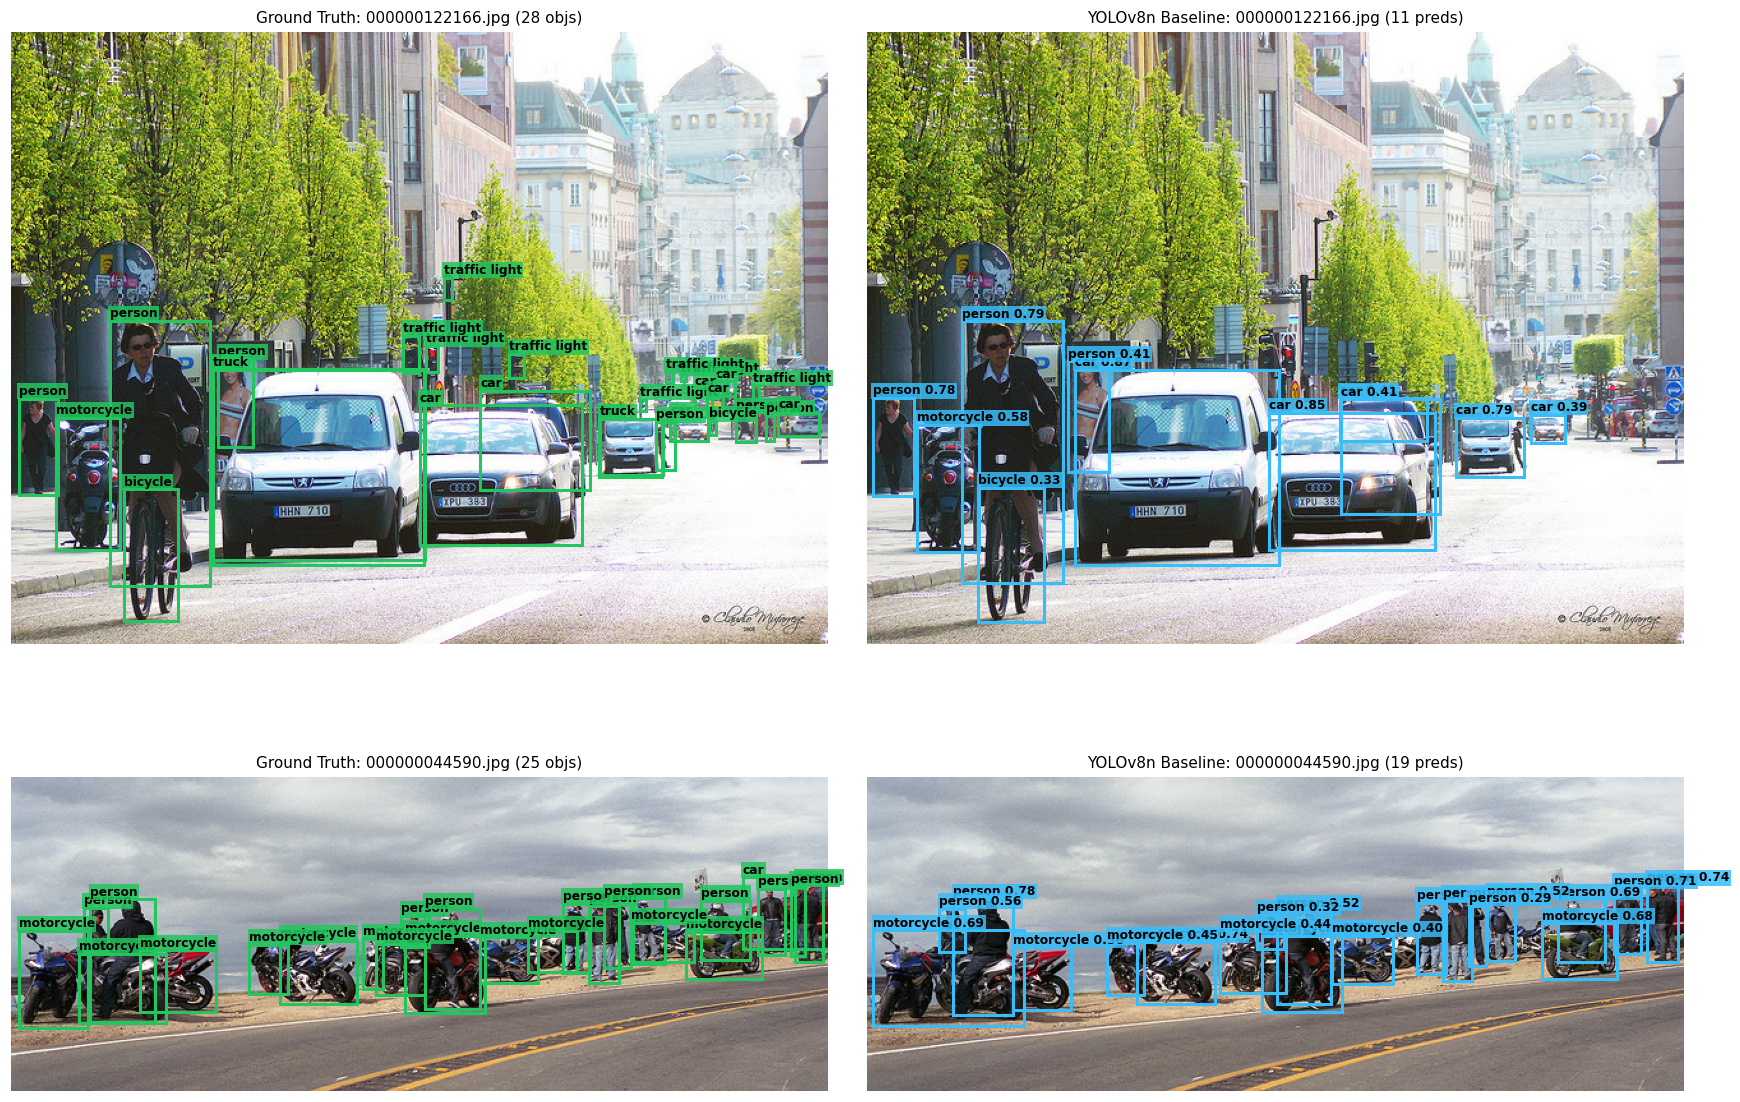

In [11]:
# ---- Cell 10: qualitative check (GT in green, predictions in cyan) ----
show = sorted(eval_records, key=lambda r: -len(r["gts"]))[:2]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for row_idx, rec_ in enumerate(show):
    img = Image.open(os.path.join(val_img_dir, rec_["file_name"])).convert("RGB")
    for col, (items, colour, title) in enumerate([
        (rec_["gts"],   "#22C55E", f"Ground Truth: {rec_['file_name']} ({len(rec_['gts'])} objs)"),
        (rec_["preds"], "#38BDF8", f"YOLOv8n Baseline: {rec_['file_name']} ({len(rec_['preds'])} preds)")]):
        ax = axes[row_idx, col]
        ax.imshow(img); ax.axis("off"); ax.set_title(title, fontsize=10)
        for it in items:
            x1, y1, x2, y2 = it["box"]
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor=colour, facecolor="none"))
            label = contiguous_to_name[it["cls"]] + (f" {it['conf']:.2f}" if "conf" in it else "")
            ax.text(x1, max(y1 - 3, 0), label, fontsize=8, fontweight="bold",
                    bbox=dict(facecolor=colour, alpha=0.85, pad=1, edgecolor="none"))
plt.tight_layout()
plt.show()

,conf_thresh,Precision,Recall,Micro_F1
0,0.05,0.509,0.747,0.605
1,0.15,0.740,0.683,0.710
2,0.25,0.837,0.633,0.721
3,0.35,0.878,0.564,0.687
4,0.45,0.894,0.494,0.637
5,0.55,0.926,0.430,0.587
6,0.65,0.960,0.373,0.537
7,0.75,0.975,0.279,0.433
8,0.85,0.991,0.160,0.276


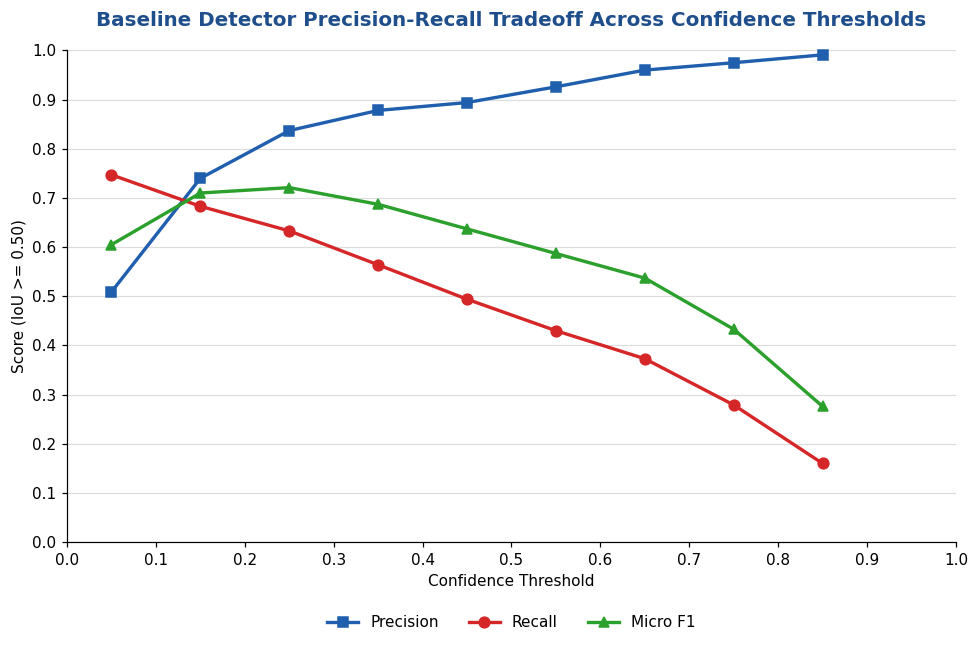

In [12]:
# ---- Cell 11: confidence-threshold sweep + graph ----
thresholds = [round(t, 2) for t in np.arange(0.05, 0.90, 0.10)]   # 0.05, 0.15, ... 0.85 (9 points)
sweep_rows = []
for t in thresholds:
    st = match_records(eval_records_all, t)
    tp = sum(v["tp"] for v in st.values()); fp = sum(v["fp"] for v in st.values()); fn = sum(v["fn"] for v in st.values())
    p_ = tp / (tp + fp) if (tp + fp) else 0.0
    r_ = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * p_ * r_ / (p_ + r_) if (p_ + r_) else 0.0
    sweep_rows.append({"conf_thresh": t, "Precision": round(p_, 3), "Recall": round(r_, 3), "Micro_F1": round(f1, 3)})
sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df)

# Line chart in the same style as the reference figure
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(sweep_df["conf_thresh"], sweep_df["Precision"], color="#1F5FAE", marker="s", linewidth=2.2, markersize=6, label="Precision", clip_on=False)
ax.plot(sweep_df["conf_thresh"], sweep_df["Recall"],    color="#D62728", marker="o", linewidth=2.2, markersize=7, label="Recall",    clip_on=False)
ax.plot(sweep_df["conf_thresh"], sweep_df["Micro_F1"],  color="#2CA02C", marker="^", linewidth=2.2, markersize=7, label="Micro F1", clip_on=False)
ax.set_title("Baseline Detector Precision-Recall Tradeoff Across Confidence Thresholds",
             fontsize=13, fontweight="bold", color="#1F4E8C", pad=16)
ax.set_xlabel("Confidence Threshold")
ax.set_ylabel("Score (IoU >= 0.50)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xticks(np.arange(0, 1.01, 0.1))
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
ax.grid(True, axis="y", color="#DDDDDD", linewidth=0.8); ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

In [13]:
# ---- Cell 12: error analysis by object size ----
missed_areas, detected_areas = [], []
for r in eval_records:
    matched = set()
    for p in sorted(r["preds"], key=lambda x: x["conf"], reverse=True):
        best_iou, best_idx = 0.0, -1
        for idx, gt in enumerate(r["gts"]):
            if idx in matched or gt["cls"] != p["cls"]:
                continue
            iou = compute_iou(p["box"], gt["box"])
            if iou > best_iou:
                best_iou, best_idx = iou, idx
        if best_iou >= IOU_THRESH and best_idx != -1:
            matched.add(best_idx)
    for idx, gt in enumerate(r["gts"]):
        area = (gt["box"][2] - gt["box"][0]) * (gt["box"][3] - gt["box"][1])
        (detected_areas if idx in matched else missed_areas).append(area)

med_det  = float(np.median(detected_areas)) if detected_areas else 0.0
med_miss = float(np.median(missed_areas))   if missed_areas   else 0.0
print(f"Detected Objects Count : {len(detected_areas)} | Median Box Area: {med_det:.0f} px^2")
print(f"Missed (FN) Objects    : {len(missed_areas)} | Median Box Area: {med_miss:.0f} px^2")

Detected Objects Count : 443 | Median Box Area: 6649 px^2
Missed (FN) Objects    : 257 | Median Box Area: 374 px^2


In [14]:
# ---- Cell 13: inference speed ----
_ = model.predict(source=val_paths[:2], verbose=False)     # warm-up
t0 = time.perf_counter()
_ = model.predict(source=val_paths, classes=list(coco80_to_subset8.keys()), conf=CONF_DEFAULT, verbose=False)
elapsed = time.perf_counter() - t0
ms_per_img = elapsed / len(val_paths) * 1000
fps = len(val_paths) / elapsed
print(f"Baseline YOLOv8n Speed: {ms_per_img:.1f} ms/image ({fps:.1f} FPS) across {len(val_paths)} images.")

Baseline YOLOv8n Speed: 297.9 ms/image (3.4 FPS) across 150 images.


In [15]:
# ---- Cell 14: save outputs ----
metrics_csv_path = os.path.join(week7_dir, "week7_baseline_metrics.csv")
metrics_df.to_csv(metrics_csv_path, index=False)
sweep_df.to_csv(os.path.join(week7_dir, "week7_conf_sweep.csv"), index=False)

preds_json_path = os.path.join(week7_dir, "week7_val_predictions.json")
with open(preds_json_path, "w", encoding="utf-8") as pf:
    json.dump(eval_records, pf, indent=2)

print(f"Saved per-class metrics table to : {metrics_csv_path}")
print(f"Saved validation predictions to  : {preds_json_path}")

Saved per-class metrics table to : ./coco_week7_baseline/week7_baseline_metrics.csv
Saved validation predictions to  : ./coco_week7_baseline/week7_val_predictions.json


In [16]:
# ---- Cell 15: final summary report ----
macro_f1 = metrics_df[metrics_df["GT"] > 0]["F1@0.5"].mean()
best_row = sweep_df.loc[sweep_df["Micro_F1"].idxmax()]
size_note = ("Missed objects are noticeably smaller than detected ones" if med_miss < 0.8 * med_det
             else "Missed objects are not markedly smaller than detected ones")

week7_report = f"""
====================================================================
DLAC HANDOUT - WEEK 7 BASELINE DETECTOR EVALUATION SUMMARY
====================================================================
1. Baseline Model        : YOLOv8-Nano (Pretrained on MS COCO, 640x640)
2. Validation Split      : {len(val_paths)} images ({total_gt} ground-truth traffic instances)
3. Macro F1 @ IoU=0.50   : {macro_f1:.3f} (at default conf={CONF_DEFAULT})
4. Optimal Conf Sweep    : conf={best_row['conf_thresh']:.2f} yields Micro-F1={best_row['Micro_F1']:.3f}
                           (Precision={best_row['Precision']:.3f}, Recall={best_row['Recall']:.3f})
5. Error Pattern Audit   : {size_note}
                           (median area missed {med_miss:.0f} px^2 vs detected {med_det:.0f} px^2)
6. Inference Throughput  : {ms_per_img:.1f} ms/image ({fps:.1f} FPS)
7. Domain Readiness Note : Establishes COCO reference baseline only; transfer learning
                           on Indian traffic imagery (IDD) is required next to handle
                           local vehicle classes (auto-rickshaws, two-wheeler density).
====================================================================
"""
print(week7_report)


DLAC HANDOUT - WEEK 7 BASELINE DETECTOR EVALUATION SUMMARY
1. Baseline Model        : YOLOv8-Nano (Pretrained on MS COCO, 640x640)
2. Validation Split      : 150 images (700 ground-truth traffic instances)
3. Macro F1 @ IoU=0.50   : 0.568 (at default conf=0.25)
4. Optimal Conf Sweep    : conf=0.25 yields Micro-F1=0.721
                           (Precision=0.837, Recall=0.633)
5. Error Pattern Audit   : Missed objects are noticeably smaller than detected ones
                           (median area missed 374 px^2 vs detected 6649 px^2)
6. Inference Throughput  : 297.9 ms/image (3.4 FPS)
7. Domain Readiness Note : Establishes COCO reference baseline only; transfer learning
                           on Indian traffic imagery (IDD) is required next to handle
                           local vehicle classes (auto-rickshaws, two-wheeler density).

